# Decision Tree & Random Forest
**F20DL Group 15 – Requirement R3 (classic ML models)** · Models: Decision Tree, Random Forest

Task: 5-class skin-disease classification on our cleaned Fitzpatrick17k subset (1,623 images).
Protocol shared by the whole group: fixed stratified split (train 1,136 / val 243 / test 244, seed 42) loaded only with
`load_split`; images resized to 32×32 RGB and flattened (3,072 features); **hyperparameters chosen on the validation set
using macro-F1**; the test set is used **once** at the very end. `random_state=42` everywhere and class imbalance handled
where the model supports it.

**Run order:** run this notebook first; `R3_knn_nb_logreg.ipynb` reads the saved test scores from `results/` to build the combined R3 table.

## 1. Setup and package versions

In [1]:
import os, sys
DATA_DIR = next(p for p in ["../Fitzpatrick17k_processed", "Fitzpatrick17k_processed"] if os.path.exists(p))
sys.path.append(DATA_DIR)
from load_data import load_split, load_info, CLASS_NAMES

import sys, time, json, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib, sklearn
import matplotlib.pyplot as plt
from sklearn.metrics import (f1_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_fscore_support)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)
# Figures go to the repo's documentation/figures/ when run from notebooks/
FIG_DIR = Path("../documentation/figures") if Path("../documentation").exists() else Path("figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Exact package versions (required by the coursework brief)
print("python      ", platform.python_version())
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib  ", matplotlib.__version__)
try:
    import PIL; print("pillow      ", PIL.__version__)
except ImportError:
    pass

python       3.13.18
numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1
matplotlib   3.11.2
pillow       13.0.0


## 2. Load the shared split

In [2]:
# Shared fixed split (seed 42). Classic models use 32x32 RGB images flattened to 3,072 features in [0, 1].
X_train, y_train = load_split("train", size=32, flatten=True)
X_val,   y_val   = load_split("val",   size=32, flatten=True)
X_test,  y_test  = load_split("test",  size=32, flatten=True)
SHORT = ["ACD", "BCC", "Psor", "SebD", "Vit"]   # short labels for plots (same order as CLASS_NAMES)

print("train", X_train.shape, "val", X_val.shape, "test", X_test.shape)
print(pd.DataFrame({s: np.bincount(y, minlength=len(CLASS_NAMES)) for s, y in
                    [("train", y_train), ("val", y_val), ("test", y_test)]}, index=CLASS_NAMES))

train (1136, 3072) val (243, 3072) test (244, 3072)
                             train  val  test
allergic contact dermatitis    267   57    57
basal cell carcinoma           248   53    54
psoriasis                      423   91    90
seborrheic dermatitis           86   18    19
vitiligo                       112   24    24


## 3. Helper functions (validation search + one-off test evaluation)

In [3]:
def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro")

def tune_on_val(make_model, grid, name):
    """Fit one model per hyperparameter setting on TRAIN, score macro-F1 on VAL.
    The test set is never touched here."""
    rows = []
    for params in grid:
        t0 = time.time()
        m = make_model(**params).fit(X_train, y_train)
        rows.append({**params,
                     "train_macro_f1": macro_f1(y_train, m.predict(X_train)),
                     "val_macro_f1": macro_f1(y_val, m.predict(X_val)),
                     "val_acc": accuracy_score(y_val, m.predict(X_val)),
                     "fit_s": round(time.time() - t0, 2)})
    df = pd.DataFrame(rows).sort_values("val_macro_f1", ascending=False).reset_index(drop=True)
    df.to_csv(RESULTS_DIR / f"{name}_val_search.csv", index=False)
    return df

def best_params(df, keys):
    row = df.iloc[0]
    out = {}
    for k in keys:
        v = row[k]
        if isinstance(v, float) and np.isnan(v): v = None
        elif isinstance(v, np.integer): v = int(v)
        elif isinstance(v, np.floating) and float(v).is_integer() and k not in FLOAT_KEYS: v = int(v)
        elif isinstance(v, np.floating): v = float(v)
        out[k] = v
    return out

FLOAT_KEYS = {"C", "var_smoothing", "max_features"}

def evaluate_on_test(model, name, params):
    """Final, one-off evaluation on the held-out TEST set + saved outputs for the report."""
    y_pred = model.predict(X_test)
    acc, mf1 = accuracy_score(y_test, y_pred), macro_f1(y_test, y_pred)
    p, r, f, s = precision_recall_fscore_support(y_test, y_pred, labels=range(len(CLASS_NAMES)), zero_division=0)
    print(f"{name}: TEST accuracy = {acc:.3f} | TEST macro-F1 = {mf1:.3f}\n")
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=3, zero_division=0))

    fig, ax = plt.subplots(figsize=(4.6, 4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=SHORT).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name} (test) – macro-F1 {mf1:.2f}")
    plt.tight_layout(); fig.savefig(FIG_DIR / f"cm_{name}.png", dpi=200); plt.show()

    res = {"model": name, "test_accuracy": round(acc, 4), "test_macro_f1": round(mf1, 4),
           "params": json.dumps(params, default=str)}
    for i, c in enumerate(SHORT):
        res[f"P_{c}"], res[f"R_{c}"] = round(p[i], 3), round(r[i], 3)
    pd.DataFrame([res]).to_csv(RESULTS_DIR / f"test_{name}.csv", index=False)
    return res

## 4. Decision Tree

**Why these hyperparameters?**
- `max_depth` ∈ {3, 5, 8, 12, 20, None} and `min_samples_leaf` ∈ {1, 5, 10, 20}: these are the two main controls on tree size.
  With only 1,136 training images and 3,072 noisy pixel features an unrestricted tree memorises the training set, so we search from
  very shallow (high bias) to fully grown (high variance) trees and let validation macro-F1 pick the trade-off.
- `criterion` ∈ {gini, entropy}: the two standard impurity measures; we check both rather than assume.
- `class_weight="balanced"` (fixed): seborrheic dermatitis (123 images) and vitiligo (160) are much rarer than psoriasis (604);
  weighting each class inversely to its frequency stops the tree from ignoring minority classes, which matters for macro-F1.

In [4]:
from sklearn.tree import DecisionTreeClassifier
from itertools import product

dt_grid = [dict(max_depth=d, min_samples_leaf=l, criterion=c)
           for d, l, c in product([3, 5, 8, 12, 20, None], [1, 5, 10, 20], ["gini", "entropy"])]
make_dt = lambda **p: DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, **p)
dt_search = tune_on_val(make_dt, dt_grid, "DecisionTree")
dt_search.head(8)

,max_depth,min_samples_leaf,criterion,train_macro_f1,val_macro_f1,val_acc,fit_s
0,20.0,1,gini,0.997089,0.332862,0.382716,2.30
1,NaN,1,gini,1.000000,0.321953,0.374486,2.50
2,12.0,1,gini,0.893567,0.316626,0.349794,2.10
3,12.0,5,gini,0.762336,0.306055,0.341564,2.05
4,8.0,1,gini,0.706428,0.299450,0.329218,1.65
5,NaN,5,gini,0.810104,0.298562,0.337449,1.68
6,20.0,5,gini,0.810104,0.298562,0.337449,1.98
7,12.0,20,gini,0.537653,0.298226,0.320988,1.32


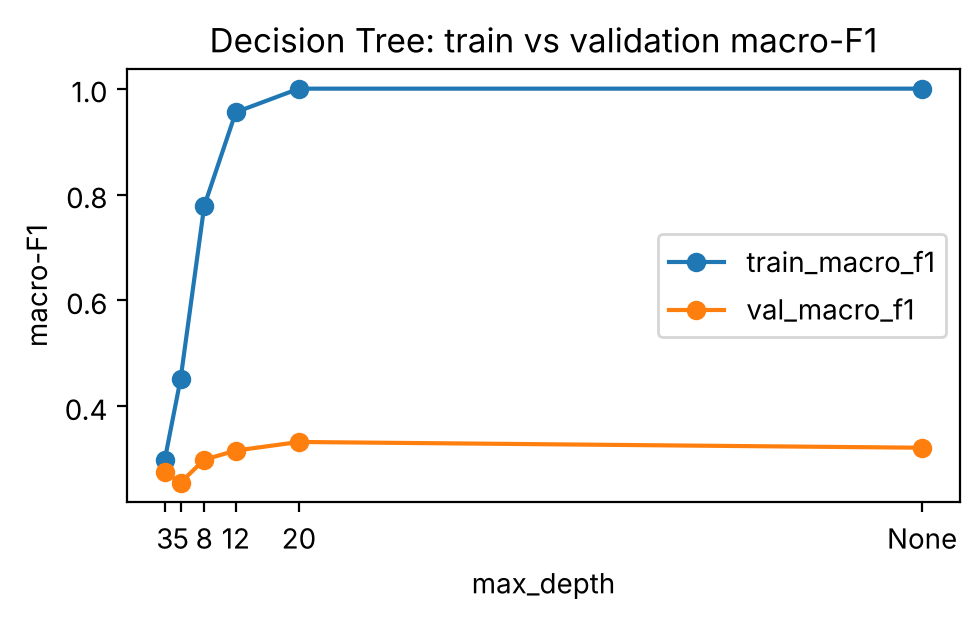

In [5]:
# Validation curve: effect of depth (best min_samples_leaf / criterion per depth)
curve = dt_search.assign(depth=dt_search.max_depth.fillna(99)).groupby("depth")[["train_macro_f1", "val_macro_f1"]].max()
ax = curve.plot(marker="o", figsize=(5, 3.2)); ax.set_xticks(curve.index)
ax.set_xticklabels([("None" if d == 99 else int(d)) for d in curve.index]); ax.set_xlabel("max_depth"); ax.set_ylabel("macro-F1")
ax.set_title("Decision Tree: train vs validation macro-F1"); plt.tight_layout(); plt.savefig(FIG_DIR / "dt_depth_curve.png", dpi=200); plt.show()

Chosen Decision Tree hyperparameters (by validation macro-F1): {'max_depth': 20, 'min_samples_leaf': 1, 'criterion': 'gini'}


DecisionTree: TEST accuracy = 0.365 | TEST macro-F1 = 0.307

                             precision    recall  f1-score   support

allergic contact dermatitis      0.364     0.351     0.357        57
       basal cell carcinoma      0.357     0.370     0.364        54
                  psoriasis      0.477     0.456     0.466        90
      seborrheic dermatitis      0.136     0.158     0.146        19
                   vitiligo      0.200     0.208     0.204        24

                   accuracy                          0.365       244
                  macro avg      0.307     0.309     0.307       244
               weighted avg      0.370     0.365     0.367       244



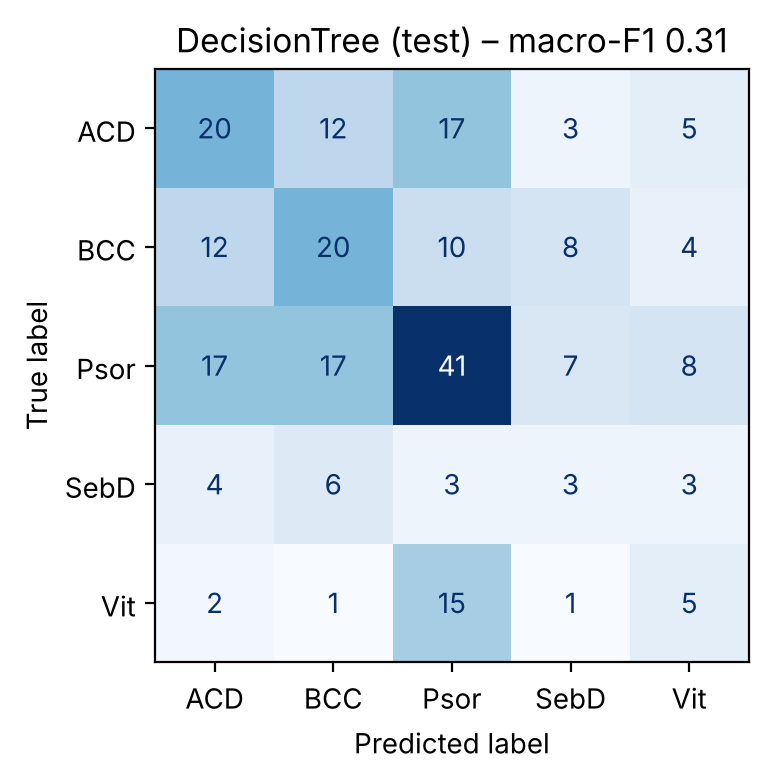

In [6]:
dt_best = best_params(dt_search, ["max_depth", "min_samples_leaf", "criterion"])
print("Chosen Decision Tree hyperparameters (by validation macro-F1):", dt_best)
dt_model = make_dt(**dt_best).fit(X_train, y_train)
dt_res = evaluate_on_test(dt_model, "DecisionTree", dt_best)